**PRACTICAL LECTURE 3**

**PART1. Autoencoders**

**2025-2026**

1. Import libraries

In [1]:
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import MNIST
from matplotlib import pyplot as plt
import numpy as np

2. Convert vector to image
The following function allows to convert a vector to an image

In [2]:
def to_img(x):
    x = 0.5 * (x + 1)
    x = x.view(x.size(0), 28, 28)
    return x

3. We now write a function which allows to display the images using the imshow() function.

In [3]:
def display_images(in_, out, n=1):
    for N in range(n):
        if in_ is not None:
            in_pic = to_img(in_.cpu().data)
            plt.figure(figsize=(18, 6))
            for i in range(4):
                plt.subplot(1,4,i+1)
                plt.imshow(in_pic[i+4*N])
                plt.axis('off')
        out_pic = to_img(out.cpu().data)
        plt.figure(figsize=(18, 6))
        for i in range(4):
            plt.subplot(1,4,i+1)
            plt.imshow(out_pic[i+4*N])
            plt.axis('off')

4. Define a data loading step and load the MNIST dataset (train and test sets).

In [4]:
batch_size = 256

img_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = MNIST('./data', transform=img_transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

test_dataset = MNIST('./data', train=False, transform=img_transform, download=True)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 333kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.86MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.21MB/s]


5. Fix the used device

In [5]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

6. Define the Autoencoder model architecture and reconstruction loss
with :
n = 28 x 28 = 784

A. Use d = 30  for standard AE (under-complete hidden layer)

B. Use d = 500 for denoising AE (over-complete hidden layer)

C. Compute **by hand** the number of parameters of the autoencoder for d = 30 and for d = 500, then check your answer with `sum(p.numel() for p in model.parameters())`.

D. Explain the difference between standard AE and denoising AE. Why would an over-complete standard AE (d = 500, no noise) be useless?
Analyse the results and conclude.

In [6]:
d=30

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, d),
            nn.Tanh(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(d, 28 * 28),
            nn.Tanh(),
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

model = Autoencoder().to(device)
criterion = nn.MSELoss()

7. Configure the optimiser. We use here : learning_rate equals to 1e-3

In [7]:
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)

8. Train the standard autoencoder and the denoising autoencoder using the following code :

epoch [1/20], loss:0.0028
epoch [2/20], loss:0.0030
epoch [3/20], loss:0.0030
epoch [4/20], loss:0.0030
epoch [5/20], loss:0.0029
epoch [6/20], loss:0.0028
epoch [7/20], loss:0.0027
epoch [8/20], loss:0.0027
epoch [9/20], loss:0.0028
epoch [10/20], loss:0.0027
epoch [11/20], loss:0.0029
epoch [12/20], loss:0.0028
epoch [13/20], loss:0.0027
epoch [14/20], loss:0.0029
epoch [15/20], loss:0.0029
epoch [16/20], loss:0.0032
epoch [17/20], loss:0.0030
epoch [18/20], loss:0.0031
epoch [19/20], loss:0.0028
epoch [20/20], loss:0.0029


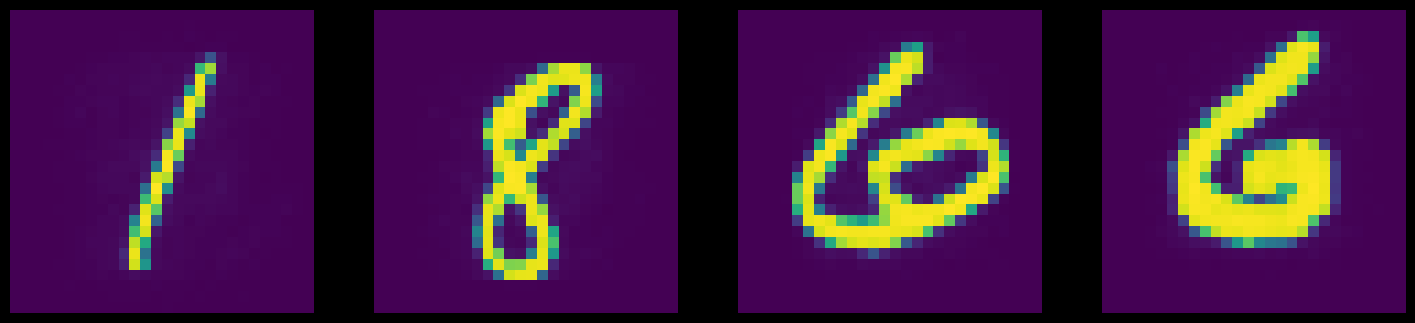

In [30]:
num_epochs = 20
# do = nn.Dropout()  # comment out for standard AE
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        # noise = do(torch.ones(img.shape)).to(device)
        # img_bad = (img * noise).to(device)  # comment out for standard AE
        # ===================forward=====================
        output = model(img)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion(output, img.data)
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(None, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

9. The Dropout noise above sets random pixels to zero. Write a second version of the denoising AE (d = 500) where the noise is **additive Gaussian noise** of standard deviation $\sigma = 0.5$ (be careful to keep the pixel values in $[-1, 1]$). Display noisy inputs and reconstructions, and compare with the Dropout version.

epoch [1/20], loss:0.0451
epoch [2/20], loss:0.0311
epoch [3/20], loss:0.0242
epoch [4/20], loss:0.0251
epoch [5/20], loss:0.0212
epoch [6/20], loss:0.0226
epoch [7/20], loss:0.0219
epoch [8/20], loss:0.0216
epoch [9/20], loss:0.0226
epoch [10/20], loss:0.0217
epoch [11/20], loss:0.0204
epoch [12/20], loss:0.0202
epoch [13/20], loss:0.0211
epoch [14/20], loss:0.0202
epoch [15/20], loss:0.0189
epoch [16/20], loss:0.0192
epoch [17/20], loss:0.0201
epoch [18/20], loss:0.0189
epoch [19/20], loss:0.0191
epoch [20/20], loss:0.0184


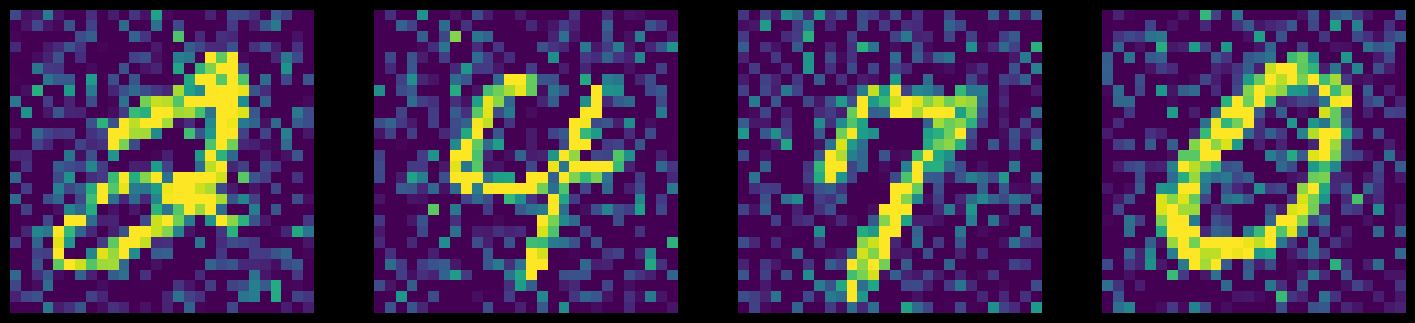

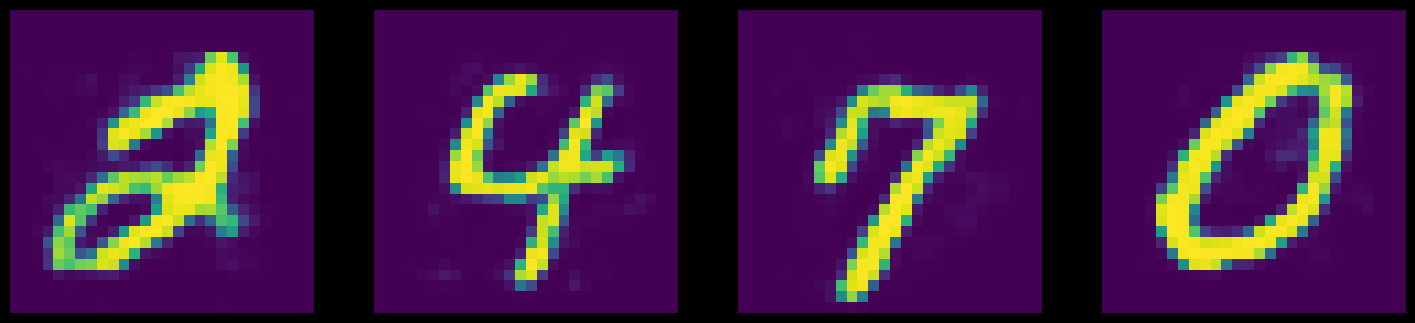

In [31]:
d = 500
model = Autoencoder().to(device)
criterion = nn.MSELoss()
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)
num_epochs = 20
# do = nn.Dropout()  # comment out for standard AE
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)

        # on remplace bruit dropout par gaussian
        noise = (torch.randn_like(img) * 0.5).to(device)
        # "additif"
        img_bad = img + noise
        # les valeurs de pixels doivent etre comprises entre -1 et 1
        img_bad = torch.clamp(img_bad, min = -1.0, max=1.0)
        
        # ===================forward=====================
        output = model(img_bad)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion(output, img.data)
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(img_bad, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

10. Visualise a few kernels of the encoder :

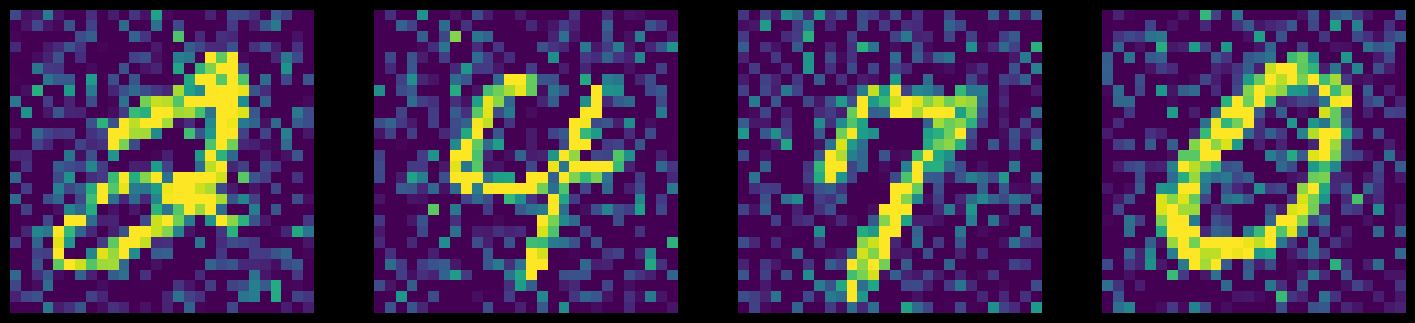

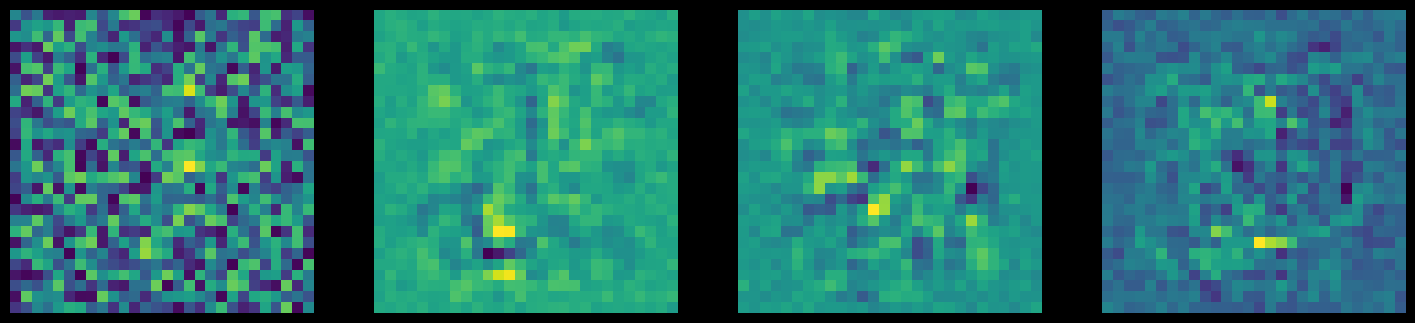

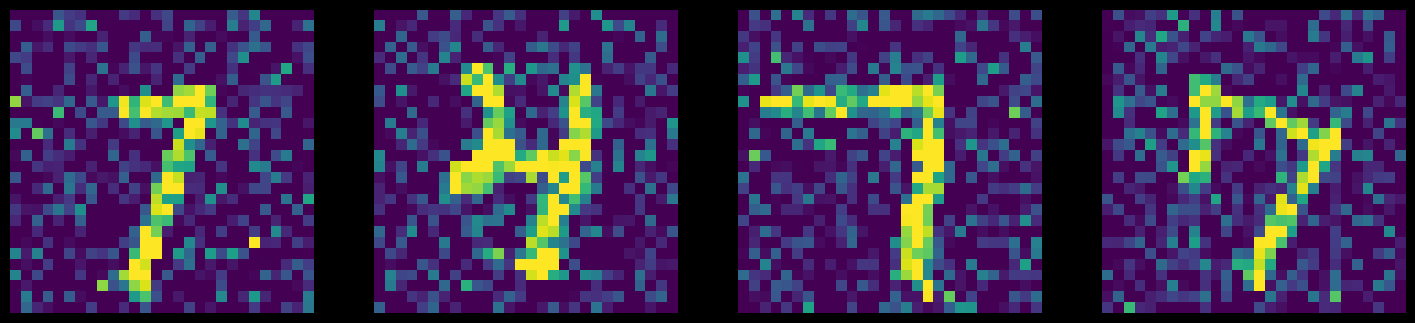

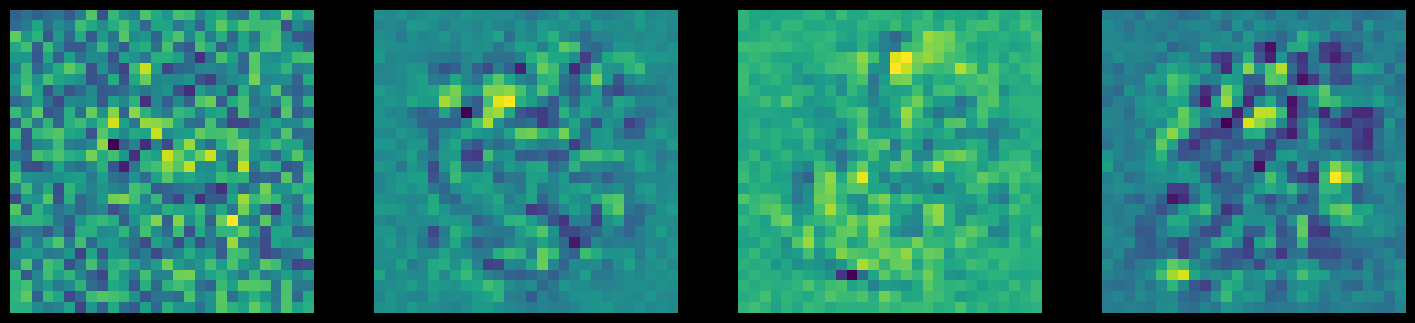

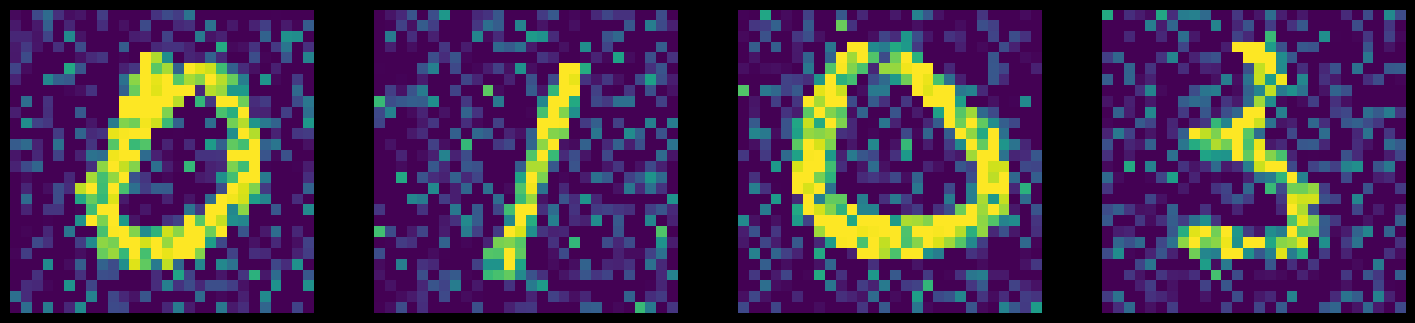

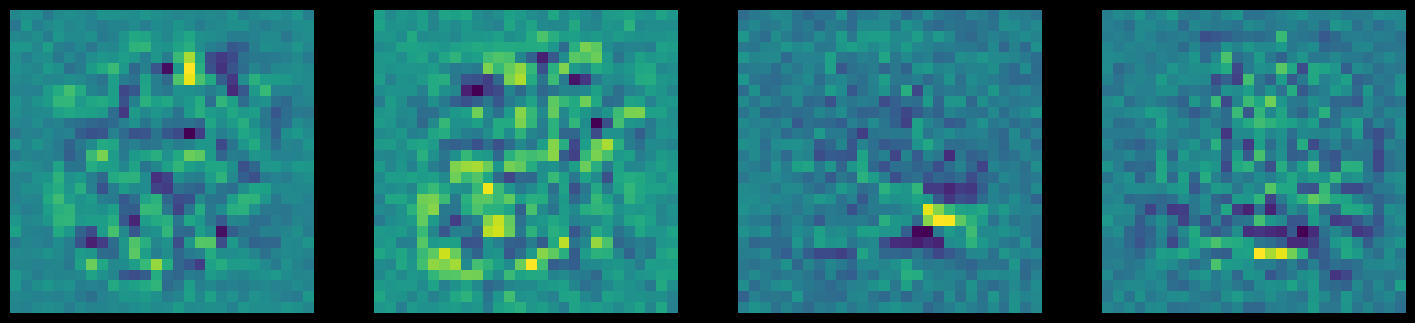

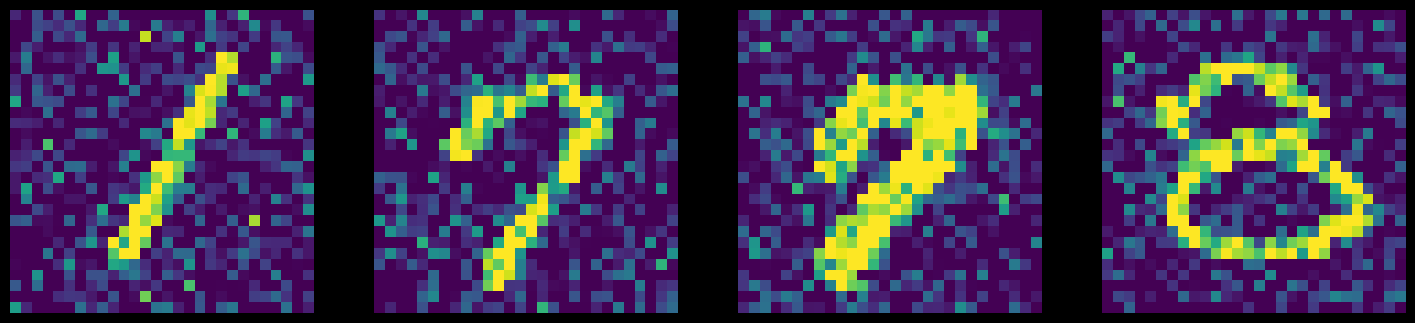

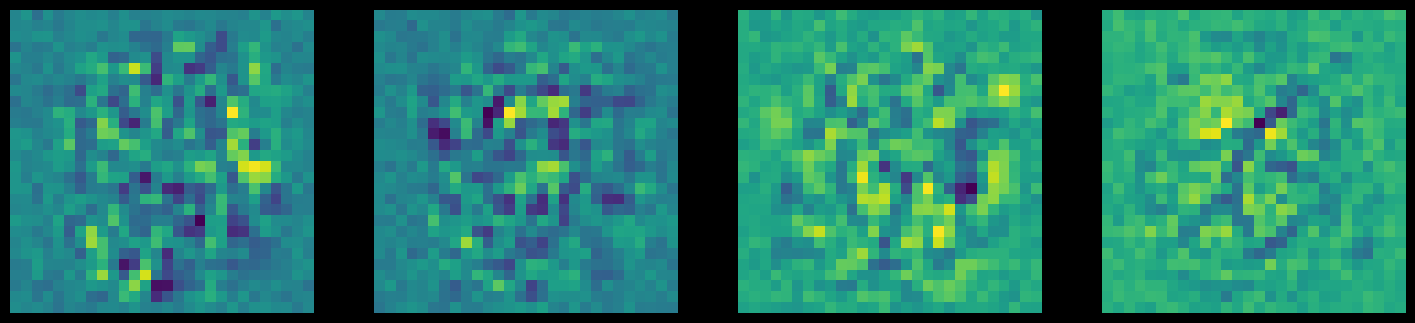

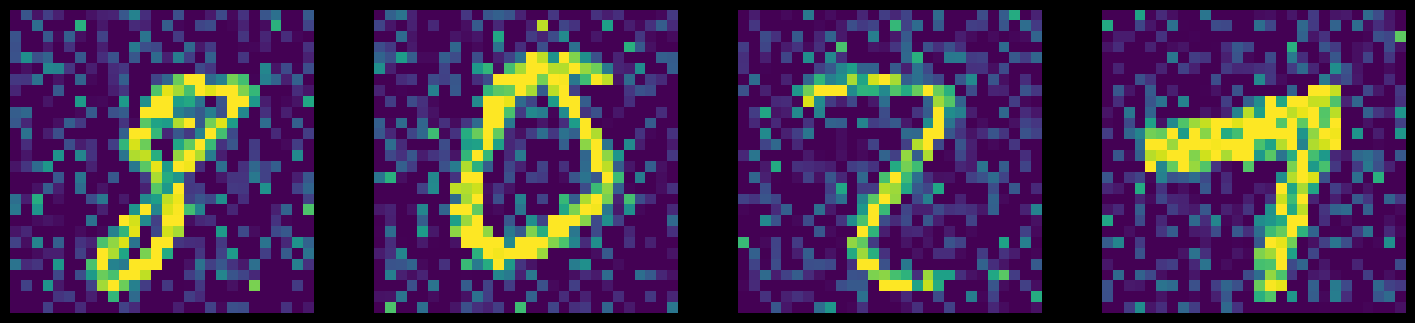

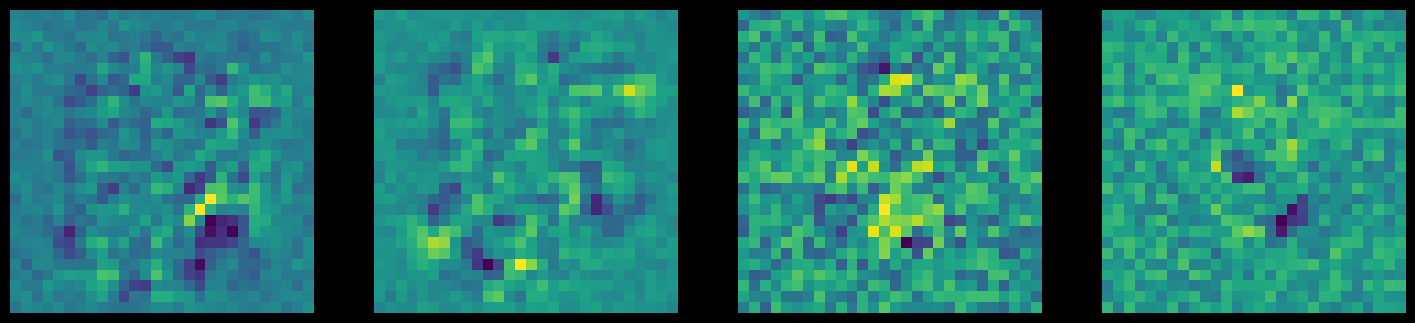

In [32]:
display_images(img_bad, model.encoder[0].weight, 5)

11. Latent space. Train a standard autoencoder with **d = 2** (5 epochs are enough). Encode all the images of the test set and plot the 2-D codes as a scatter plot, with one color per digit (use the labels of `test_dataset`). Which digits are well separated? Which ones overlap? Is this surprising, given that the labels were never used during training?

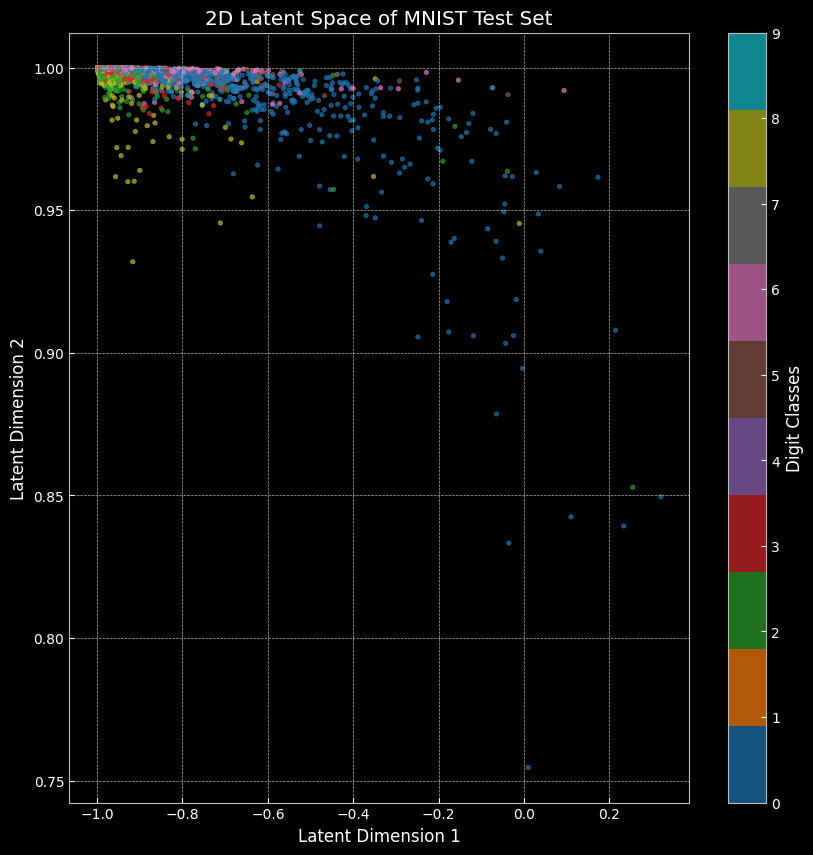

In [33]:
d = 2
model_2d = Autoencoder().to(device)
criterion = nn.MSELoss()
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model_2d.parameters(),
    lr=learning_rate,
)

num_epochs = 5

model_2d.train()

for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        
        output = model_2d(img)
        loss = criterion(output, img)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

latent_codes = []
labels_list = []

model_2d.eval()
with torch.no_grad(): # No need to track gradients for evaluation
    for data in test_dataloader:
        img, label = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        
        code = model_2d.encoder(img)
        latent_codes.append(code)
        labels_list.append(label) 
# on fusuonne les petits lots
latent_codes = torch.cat(latent_codes).numpy()
labels_list = torch.cat(labels_list).numpy()

plt.figure()
scatter = plt.scatter(latent_codes[:, 0], latent_codes[:, 1], c=labels_list, cmap='tab10', alpha=0.7, s=10)
plt.colorbar(scatter, ticks=range(10), label='Digit Classes')
plt.title("2D Latent Space of MNIST Test Set")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.show()

Réponse question 11 :
- avec d = 2, l’espace latent n'est pas très lisible (c'est très concentrés dans un coin) c'est dû au fait que l’activation tanh de l’encodeur sature (car avec que 2 neurones les poids grandissent et les sorties collent aux bornes [-1,+1])
- chiffre bien séparé : le 0 s'étale loin des autres classes
- chiffres qui se chevauchent : toutes les autres classes sont mélangées dans le coin saturé
- c'est pas surprenant car l’autoencodeur n’utilise jamais les labels, mais pour reconstruire les images il doit placer proches les images qui se ressemblent en pixels et les images d’un même chiffre se ressemblent plus entre elles qu’avec les autres mais 2 dimensions sont trop peu pour séparer 10 classes, et la saturation du tanh écrase une grande partie des points

12. Write a function `test_mse(model)` returning the mean reconstruction error on the **test set**. Train a standard AE (5 epochs each) for d ∈ {2, 10, 30, 100} and plot the test MSE as a function of d. Comment the curve.

dim 2 : epoch [1/5], loss:0.5274
dim 2 : epoch [2/5], loss:0.3271
dim 2 : epoch [3/5], loss:0.2808
dim 2 : epoch [4/5], loss:0.2769
dim 2 : epoch [5/5], loss:0.2676
dim 10 : epoch [1/5], loss:0.2922
dim 10 : epoch [2/5], loss:0.2559
dim 10 : epoch [3/5], loss:0.2316
dim 10 : epoch [4/5], loss:0.2075
dim 10 : epoch [5/5], loss:0.1925
dim 30 : epoch [1/5], loss:0.1967
dim 30 : epoch [2/5], loss:0.1423
dim 30 : epoch [3/5], loss:0.1184
dim 30 : epoch [4/5], loss:0.1014
dim 30 : epoch [5/5], loss:0.0950
dim 100 : epoch [1/5], loss:0.1023
dim 100 : epoch [2/5], loss:0.0722
dim 100 : epoch [3/5], loss:0.0493
dim 100 : epoch [4/5], loss:0.0422
dim 100 : epoch [5/5], loss:0.0354


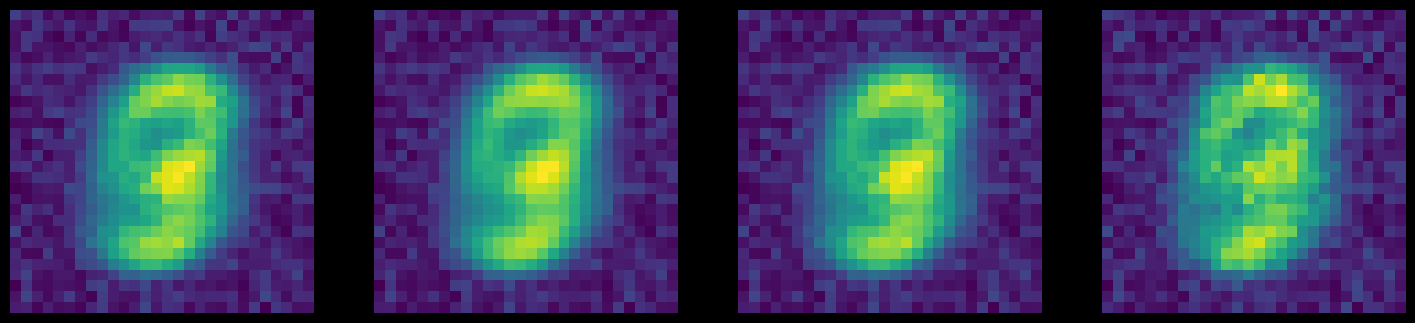

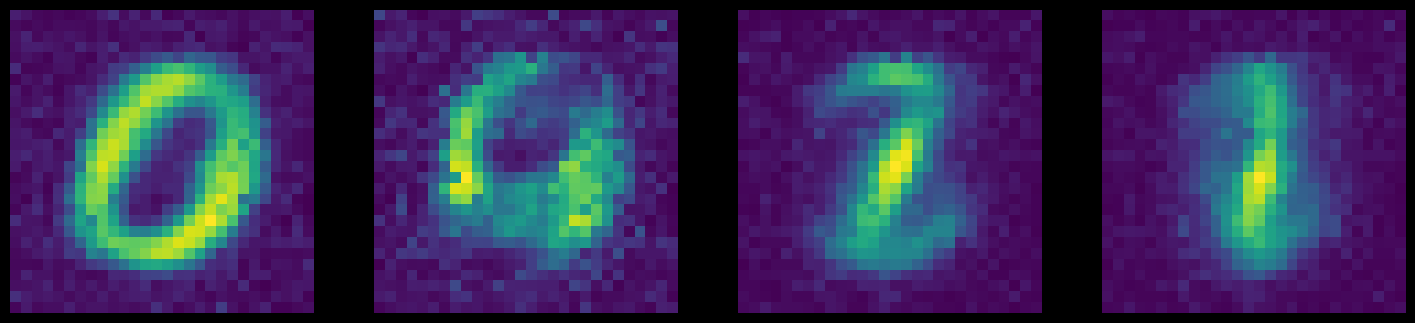

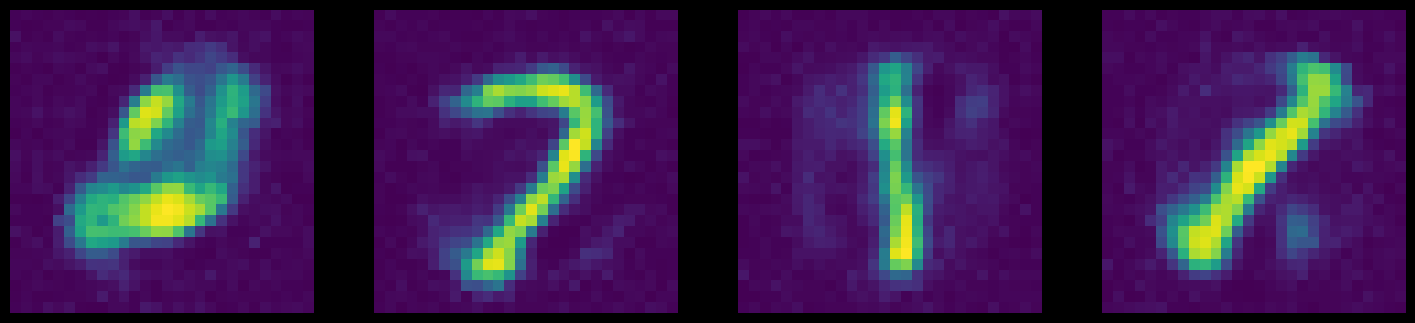

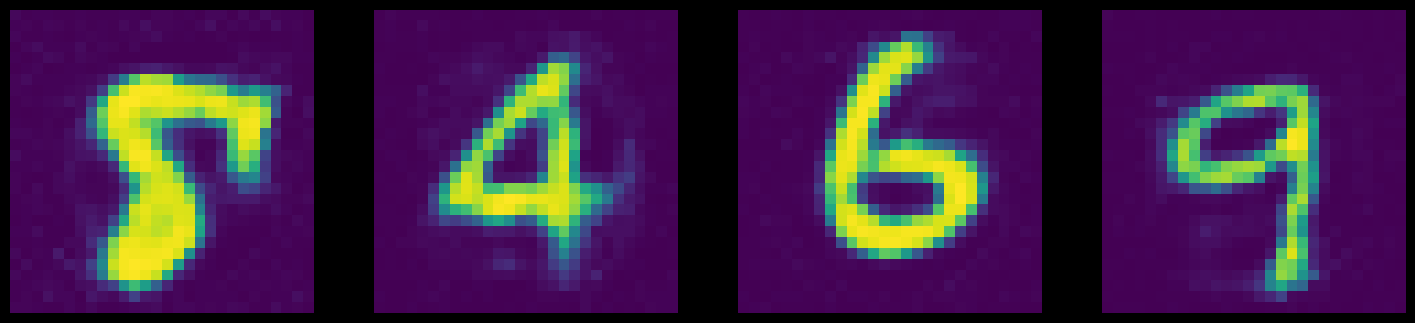

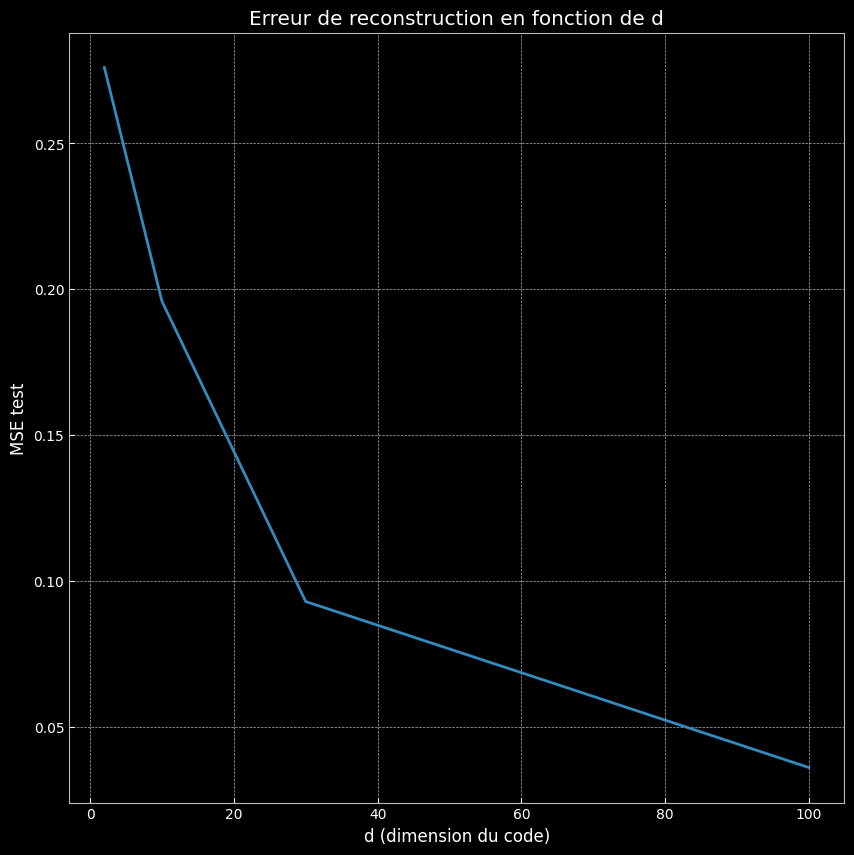

In [37]:
def test_mse(model):
    model.eval()
    total = 0
    n = 0

    with torch.no_grad():
        for data in test_dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model(img)
            dist_carre = (output - img) ** 2
            total = total + (dist_carre).sum().item()
            
            n += img.shape[0] * img.shape[1]
    return total / n

liste_mse_model = []

dim_liste = [2, 10, 30, 100]

for d_valeur in dim_liste :

    d = d_valeur
    model_2d = Autoencoder().to(device)
    criterion = nn.MSELoss()
    learning_rate = 1e-3

    optimizer = torch.optim.Adam(
        model_2d.parameters(),
        lr=learning_rate,
    )

    num_epochs = 5
    for epoch in range(num_epochs):
        for data in dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model_2d(img)
            loss = criterion(output, img.data)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f'dim {d} : epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
    display_images(None, output)

    liste_mse_model.append(test_mse(model_2d))

plt.figure()
plt.plot(dim_liste, liste_mse_model)
plt.xlabel("d (dimension du code)")
plt.ylabel("MSE test")
plt.title("Erreur de reconstruction en fonction de d")
plt.show()

13. Analyse the obtained results.

- plus les dimensions montent plus la MSE baisse, elle est maximale à d=2 ce qui est logique car on perd beaucoup d'informations en compressant une image en 2 dimensions seulement
- plus d monte plus l'espace latent a de la capacité de stockage donc moins de perte d'info donc l'erreur quadratique moyenne de reconstruction baisse

- les séries d'images reconstruites sont floues et pas nettes pour d=2
- plus d monte moins il y a de bruits et plus c'est net (on voit mieux les contours)

14. Change the parameters of the Autoencoder (activation functions, number of layers, learning rate…) and analyse their impact. Conclude.

dim 2 : epoch [1/5], loss:0.1902
dim 2 : epoch [2/5], loss:0.1716
dim 2 : epoch [3/5], loss:0.1853
dim 2 : epoch [4/5], loss:0.1749
dim 2 : epoch [5/5], loss:0.1678
dim 10 : epoch [1/5], loss:0.0805
dim 10 : epoch [2/5], loss:0.0796
dim 10 : epoch [3/5], loss:0.0686
dim 10 : epoch [4/5], loss:0.0643
dim 10 : epoch [5/5], loss:0.0634
dim 30 : epoch [1/5], loss:0.0389
dim 30 : epoch [2/5], loss:0.0304
dim 30 : epoch [3/5], loss:0.0260
dim 30 : epoch [4/5], loss:0.0251
dim 30 : epoch [5/5], loss:0.0237
dim 100 : epoch [1/5], loss:0.0358
dim 100 : epoch [2/5], loss:0.0210
dim 100 : epoch [3/5], loss:0.0159
dim 100 : epoch [4/5], loss:0.0145
dim 100 : epoch [5/5], loss:0.0118


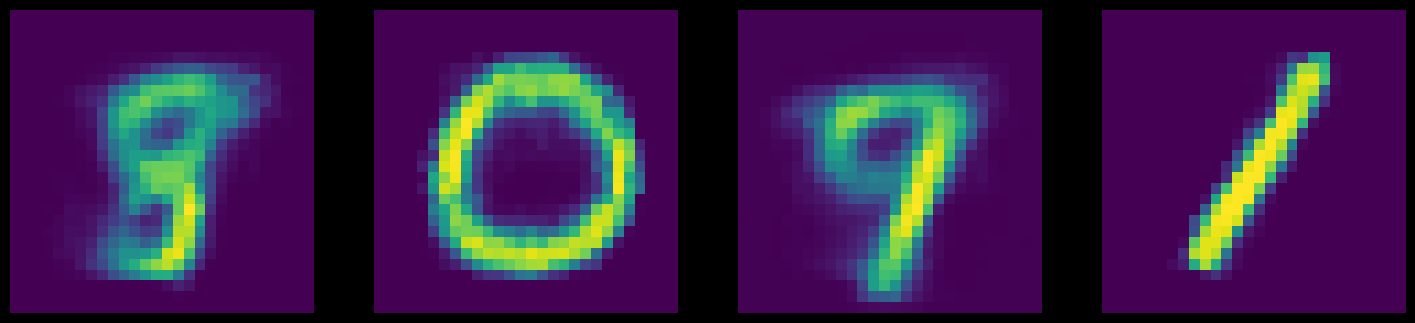

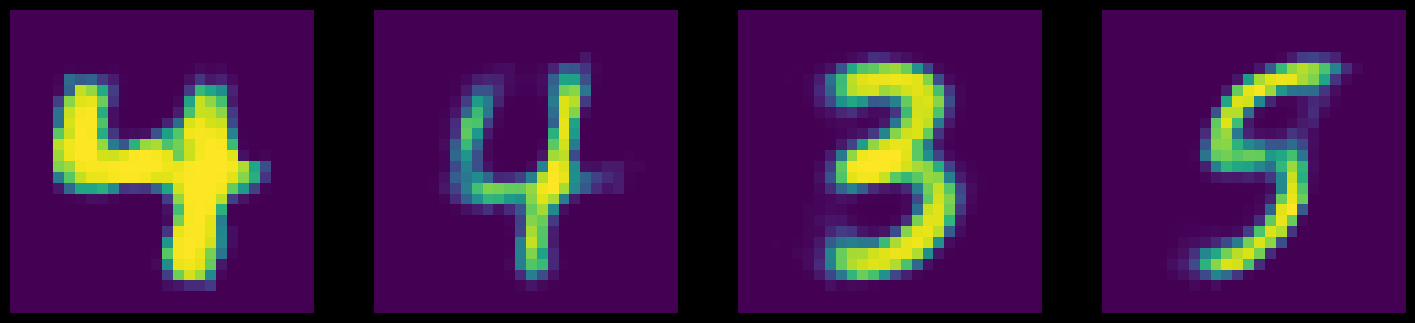

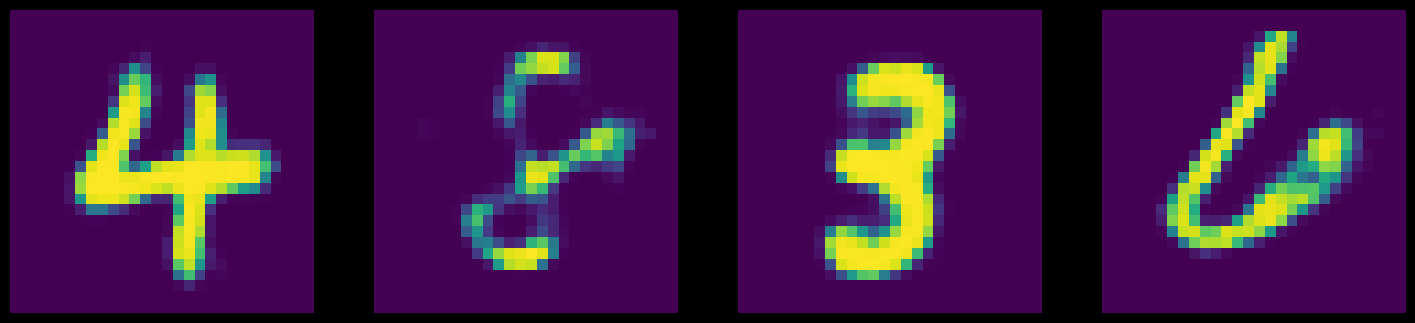

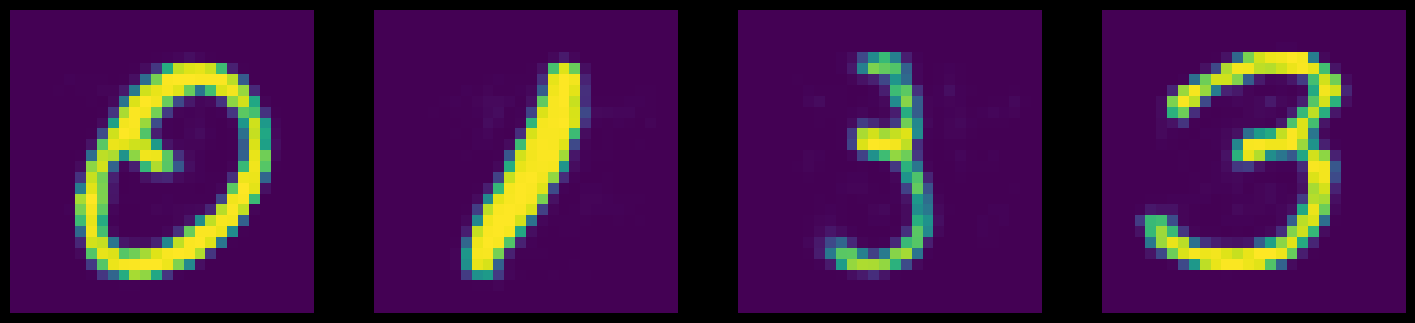

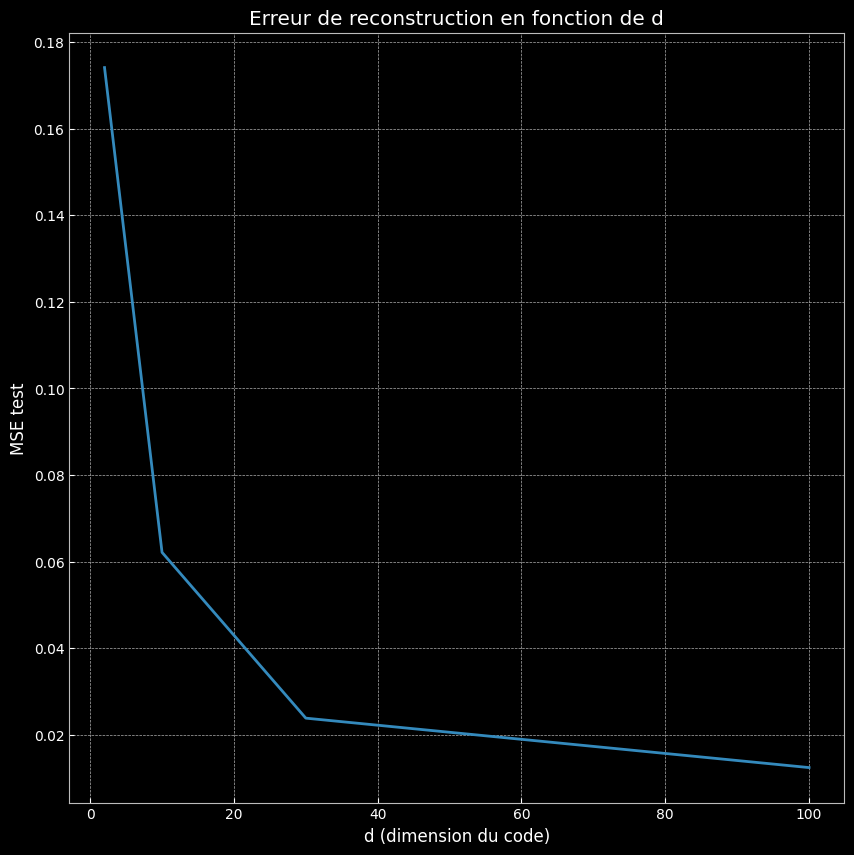

In [40]:
d=30

class Autoencoder_v2(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 50 * 50),
            nn.ReLU(),
            nn.Linear(50 * 50, d),

        )
        self.decoder = nn.Sequential(
            nn.Linear(d, 50 * 50),
            nn.ReLU(),
            nn.Linear(50*50, 28 * 28),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

liste_mse_model = []

dim_liste = [2, 10, 30, 100]

for d_valeur in dim_liste :

    d = d_valeur
    model_2d = Autoencoder_v2().to(device)
    criterion = nn.MSELoss()
    learning_rate = 1e-3

    optimizer = torch.optim.Adam(
        model_2d.parameters(),
        lr=learning_rate,
    )

    num_epochs = 5
    for epoch in range(num_epochs):
        for data in dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model_2d(img)
            loss = criterion(output, img.data)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f'dim {d} : epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
    display_images(None, output)

    liste_mse_model.append(test_mse(model_2d))

plt.figure()
plt.plot(dim_liste, liste_mse_model)
plt.xlabel("d (dimension du code)")
plt.ylabel("MSE test")
plt.title("Erreur de reconstruction en fonction de d")
plt.show()

On remarque que selon les fonctions d'activation et autres paramètres choisis, les séries d'images diffèrent en netteté : là on a un résultat bien plus propre par exemple ce qui est logique avce 2500 neurones, une activation ReLU en couche cachée et Tahn en sortie. En effet, on avait testé Sigmoid en sortie mais sur des images dans [−1, 1] ça empêche l'apprentissage.
En contrepartie c'est beaucoup plus long et coûteux.

**PART2. Convolutional Neural Networks**

1. Import the libraries and set the parameters

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np


def set_default(figsize=(10, 10), dpi=100):
    plt.style.use(['dark_background', 'bmh'])
    plt.rc('axes', facecolor='k')
    plt.rc('figure', facecolor='k')
    plt.rc('figure', figsize=figsize, dpi=dpi)

set_default()

# function to count number of parameters
def get_n_params(model):
    n = 0
    for p in list(model.parameters()):
        n += p.nelement()
    return n

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

2. Load the Dataset (MNIST) using PyTorch DataLoader utilities and visualize some images :

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 313kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.78MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.69MB/s]


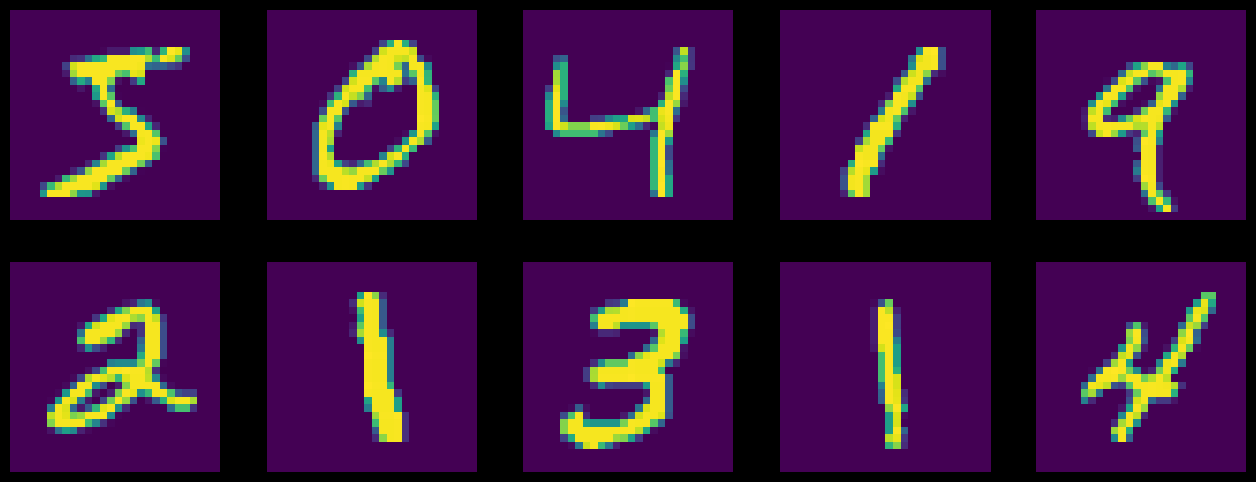

In [13]:
input_size  = 28*28   # images are 28x28 pixels
output_size = 10      # there are 10 classes

train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=True, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=64, shuffle=True)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=False, transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=1000, shuffle=True)

plt.figure(figsize=(16, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    image, _ = train_loader.dataset.__getitem__(i)
    plt.imshow(image.squeeze().numpy())
    plt.axis('off');

3. Create the model classes

In [14]:
class FC2Layer(nn.Module):
    def __init__(self, input_size, n_hidden, output_size):
        super(FC2Layer, self).__init__()
        self.input_size = input_size
        self.network = nn.Sequential(
            nn.Linear(input_size, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, output_size),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, x):
        x = x.view(-1, self.input_size)
        return self.network(x)

class CNN(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super(CNN, self).__init__()
        self.n_feature = n_feature
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=5)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=5)
        self.fc1 = nn.Linear(n_feature*4*4, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x, verbose=False):
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = x.view(-1, self.n_feature*4*4)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.log_softmax(x, dim=1)
        return x

4. a. For an input image of size 1×28×28, compute **by hand** the shape of the tensor after each layer of the CNN (conv1, pooling, conv2, pooling). Justify the value `n_feature*4*4` used in `fc1`.

   b. Use the argument `verbose` of `forward` to print these shapes and check your answer.

   c. Compute by hand the number of parameters of the CNN for `n_feature = 6` and of the FC2Layer for `n_hidden = 8`. Check with `get_n_params`.

Réponse 4.a :

D'après le cours (Relationship 6), la taille de sortie d'une convolution ou d'un pooling est :

$$o = \left\lfloor \frac{i + 2p - k}{s} \right\rfloor + 1$$

avec $i$ la taille d'entrée, $k$ la taille du noyau, $p$ le padding et $s$ le stride.

On choisit cette formule car c'est le cas général : elle contient les relations 1, 2 et 5 du cours doc en une formule on a à la fois les convolutions et les poolings du réseau, le pooling fonctionnant comme une convolution.

Dans notre CNN, `conv1` et `conv2` ont $k=5$, $s=1$, $p=0$, et `max_pool2d` a $k=2$, $s=2$, $p=0$.

5. Run on a GPU: device string

Switching between CPU and GPU in PyTorch is controlled via a device string, which will seamlessly determine whether GPU is available, falling back to CPU if not:

In [15]:
accuracy_list = []

def train(epoch, model, perm=torch.arange(0, 784).long()):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        # send to device
        data, target = data.to(device), target.to(device)

        # permute pixels
        data = data.view(-1, 28*28)
        data = data[:, perm]
        data = data.view(-1, 1, 28, 28)

        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))

def test(model, perm=torch.arange(0, 784).long()):
    model.eval()
    test_loss = 0
    correct = 0
    for data, target in test_loader:
        # send to device
        data, target = data.to(device), target.to(device)

        # permute pixels
        data = data.view(-1, 28*28)
        data = data[:, perm]
        data = data.view(-1, 1, 28, 28)
        output = model(data)
        test_loss += F.nll_loss(output, target, reduction='sum').item() # sum up batch loss
        pred = output.data.max(1, keepdim=True)[1] # get the index of the max log-probability
        correct += pred.eq(target.data.view_as(pred)).cpu().sum().item()

    test_loss /= len(test_loader.dataset)
    accuracy = 100. * correct / len(test_loader.dataset)
    accuracy_list.append(accuracy)
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        accuracy))

6. Train a small fully-connected network

In [16]:
n_hidden = 8 # number of hidden units

model_fnn = FC2Layer(input_size, n_hidden, output_size)
model_fnn.to(device)
optimizer = optim.SGD(model_fnn.parameters(), lr=0.01, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_fnn)))

for epoch in range(0, 1):
    train(epoch, model_fnn)
    test(model_fnn)

Number of parameters: 6442
Train Epoch: 0 [0/60000 (0%)]	Loss: 2.344285
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.890848
Train Epoch: 0 [12800/60000 (21%)]	Loss: 1.230594
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.885622
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.527415
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.778834
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.572588
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.501523
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.298871
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.608865

Test set: Average loss: 0.4164, Accuracy: 8771/10000 (88%)



7. Train a ConvNet with the same number of parameters

In [17]:
# Training settings
n_features = 6 # number of feature maps

model_cnn = CNN(input_size, n_features, output_size)
model_cnn.to(device)
optimizer = optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_cnn)))

for epoch in range(0, 1):
    train(epoch, model_cnn)
    test(model_cnn)

Number of parameters: 6422
Train Epoch: 0 [0/60000 (0%)]	Loss: 2.286785
Train Epoch: 0 [6400/60000 (11%)]	Loss: 2.152804
Train Epoch: 0 [12800/60000 (21%)]	Loss: 0.575709
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.422383
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.163751
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.396981
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.388937
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.375658
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.193827
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.071470

Test set: Average loss: 0.1766, Accuracy: 9457/10000 (95%)



8. Permuted pixels. Draw a fixed random permutation of the pixels with `perm = torch.randperm(784)` and display a few permuted images.

   Train a **new** FC2Layer and a **new** CNN (same sizes as above, 1 epoch) on the permuted images, using the argument `perm` of `train` and `test`.

   Compare the 4 accuracies (FC / CNN, original / permuted) in a bar chart. Explain why one model is affected by the permutation and the other is not. Which assumption on images does the CNN rely on?

9. Compute and display the confusion matrix (10×10) of the CNN trained on the original images, on the test set. Which digits are most often confused? Display 8 misclassified test images with their true and predicted labels.

10. Change the parameters of the models (number of feature maps, number of hidden units, number of epochs, learning rate).

11. Analyze the results and the impact of these parameters, in particular the trade-off between number of parameters and accuracy.